<a href="https://colab.research.google.com/github/jaiswalvik/MathematicalFoundationsOfGenerativeAI/blob/master/Assignment2_VanillaGAN_DCGAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 — Image Generation with Vanilla GAN and DCGAN

**Course:** Mathematical Foundations of Generative AI  
**Assignment:** Image Generation with Vanilla GAN and DCGAN

This notebook is a runnable implementation template for the assignment PDF. It:
- uses the same `dataset1/train` and `dataset1/test` class-folder structure as Assignment 1;
- creates a reproducible stratified train/validation split;
- trains a fully connected Vanilla GAN and a convolutional DCGAN;
- saves generated image grids at several epochs and latent interpolations;
- records generator/discriminator losses and experiment results;
- attempts FID evaluation when `torchmetrics` and its dependencies are available, with a clearly labelled feature-space proxy fallback.

**Important:** No dataset was uploaded with the assignment PDFs, so this notebook has not been trained here and contains no fabricated metrics. Run it in Google Colab after mounting your dataset. For strict compliance, keep the image size and normalization consistent with Assignment 1. The default `IMAGE_SIZE=224` follows the earlier classification notebook, but Vanilla GAN at this resolution is memory-intensive. If you hit GPU memory limits, use `64` as a practical low-resolution experiment and document this deviation in your report.

## 1. Install / import dependencies

In [1]:
%pip -q install scikit-learn matplotlib pandas pillow

In [2]:
import os, json, time, random, copy, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, utils
from sklearn.model_selection import train_test_split

print("PyTorch:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cpu":
    print("Warning: GAN training, especially at 224x224, may be very slow on CPU.")

PyTorch: 2.11.0+cu130
Device: cuda


## 2. Mount Google Drive and configure paths

Expected folder structure:

```text
dataset1/
├── train/
│   ├── class_1/
│   ├── class_2/
│   └── ...
└── test/
    ├── class_1/
    ├── class_2/
    └── ...
```

The assignment asks for the same dataset and split definitions as Assignment 1. The notebook below creates the same seeded stratified 80/20 split from `train/` and keeps `test/` separate.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

# Change this if your dataset is stored elsewhere.
DATA_DIR = Path("/content/dataset1")
# If you need to extract a ZIP from Drive, uncomment and edit:
import zipfile
ZIP_PATH = "/content/drive/MyDrive/dataset1.zip"
with zipfile.ZipFile(ZIP_PATH) as zf:
     zf.extractall("/content")

OUTPUT_DIR = Path("/content/drive/MyDrive/assignment2_gan_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 224   # Matches Assignment 1. Use 64 only if documenting a low-resolution deviation.
BATCH_SIZE = 16
EPOCHS = 1
LATENT_DIM = 100
NUM_WORKERS = 2
LEARNING_RATE = 2e-4
BETA1, BETA2 = 0.5, 0.999
VAL_FRACTION = 0.20
SAMPLE_EVERY = 1

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
assert TRAIN_DIR.is_dir(), f"Training folder not found: {TRAIN_DIR}"
assert TEST_DIR.is_dir(), f"Test folder not found: {TEST_DIR}"
print("Output:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output: /content/drive/MyDrive/assignment2_gan_outputs


## 3. Dataset, transforms, and DataLoaders

For GAN training, labels are not used in the baseline objective, but `ImageFolder` still reads class folders and the split remains aligned with Assignment 1. The discriminator's real images and generator outputs must use the same numeric scale.

The Assignment 1 notebook uses ImageNet normalization. Since the GAN architectures here use a `Tanh` generator output (range `[-1, 1]`), we map real images to `[-1,1]` using mean/std `(0.5, 0.5, 0.5)`. If strict reuse of ImageNet mean/std is required, change the generator output scaling accordingly; do not feed real and generated images on inconsistent scales.

In [4]:
# GAN-friendly normalization: ToTensor maps to [0,1], then Normalize(0.5,0.5) maps to [-1,1].
# This is consistent with a Tanh generator. Keep the same transform for train/val/test.
gan_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=gan_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=gan_transform)
class_names = train_dataset.classes
num_classes = len(class_names)
assert test_dataset.class_to_idx == train_dataset.class_to_idx, (
    "Train/test class folder mappings differ."
)
print("Classes:", num_classes, class_names)
print("Train images:", len(train_dataset), "| Test images:", len(test_dataset))
if num_classes != 10:
    print("WARNING: assignment specifies 10 classes; check the dataset.")

indices = np.arange(len(train_dataset))
targets = np.array(train_dataset.targets)
train_idx, val_idx = train_test_split(
    indices, test_size=VAL_FRACTION, random_state=SEED, stratify=targets
)
train_subset = Subset(train_dataset, train_idx)
val_subset = Subset(train_dataset, val_idx)

loader_kwargs = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"), drop_last=True
)
train_loader = DataLoader(train_subset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_subset, shuffle=False, **loader_kwargs)
# Keep test set separate; no labels are used to update either GAN.
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

print(f"Train split: {len(train_subset)} | Validation split: {len(val_subset)} | Test: {len(test_dataset)}")

Classes: 10 ['n01820546', 'n01833805', 'n01843065', 'n01843383', 'n01855032', 'n01855672', 'n01860187', 'n01872401', 'n01882714', 'n02012849']
Train images: 12341 | Test images: 500
Train split: 9872 | Validation split: 2469 | Test: 500


## 4. Inspect a real-image batch

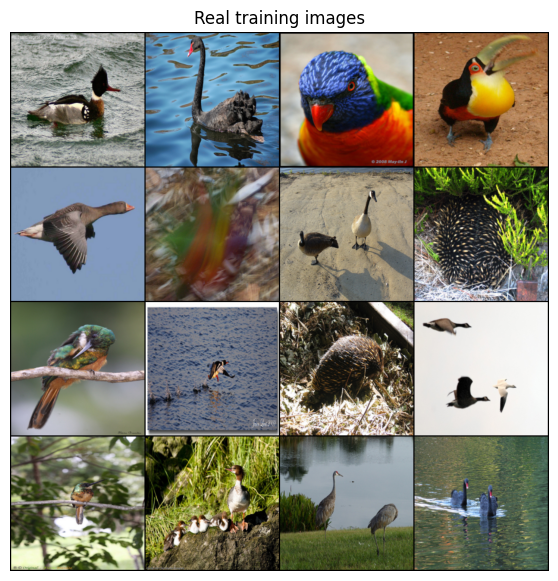

In [5]:
real_batch, label_batch = next(iter(train_loader))
grid = utils.make_grid(real_batch[:16], nrow=4, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Real training images")
plt.show()

## 5. Define the Vanilla GAN

- **Generator**: maps a random latent vector `z ~ N(0, I)` to a flattened image vector, then reshapes it into an image.
- **Discriminator**: maps an image to one logit; positive logits indicate more confidence that an image is real.
- **Loss**: `BCEWithLogitsLoss`, numerically stable binary cross entropy.

At 224×224, fully connected GAN layers are large. If memory is insufficient, reduce `IMAGE_SIZE` to 64 and rerun all data/model cells, then clearly note the resolution change in your report.

In [6]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, image_size=IMAGE_SIZE, channels=3):
        super().__init__()
        self.image_size = image_size
        self.channels = channels
        out_dim = channels * image_size * image_size
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(True),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(True),
            nn.Linear(1024, out_dim),
            nn.Tanh(),
        )

    def forward(self, z):
        x = self.net(z)
        return x.view(z.size(0), self.channels, self.image_size, self.image_size)


class VanillaDiscriminator(nn.Module):
    def __init__(self, image_size=IMAGE_SIZE, channels=3):
        super().__init__()
        in_dim = channels * image_size * image_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1),  # logits; no sigmoid with BCEWithLogitsLoss
        )

    def forward(self, x):
        return self.net(x)


vanilla_G = VanillaGenerator().to(device)
vanilla_D = VanillaDiscriminator().to(device)
print("Vanilla Generator parameters:", sum(p.numel() for p in vanilla_G.parameters()))
print("Vanilla Discriminator parameters:", sum(p.numel() for p in vanilla_D.parameters()))

Vanilla Generator parameters: 154871296
Vanilla Discriminator parameters: 154667009


## 6. Define DCGAN

The DCGAN uses strided convolutions in the discriminator and transposed convolutions in the generator, avoiding pooling layers. Batch normalization and ReLU are used in the generator; LeakyReLU is used in the discriminator. The implementation supports common power-of-two image sizes (64, 128) and 224 by using a 7×7 starting feature map followed by ×2 upsampling stages. The final layer is resized to the configured spatial resolution if needed.

In [7]:
class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, image_size=IMAGE_SIZE, channels=3, base=64):
        super().__init__()
        self.image_size = image_size
        # Start at 7x7 for 224px images; repeatedly double spatial dimensions
        # until reaching or exceeding the target, then resize only if necessary.
        start_size = 7
        stages = max(1, int(math.ceil(math.log2(image_size / start_size))))
        self.start_size = start_size
        first_channels = base * 8
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, first_channels * start_size * start_size),
            nn.BatchNorm1d(first_channels * start_size * start_size),
            nn.ReLU(True),
        )
        layers = []
        in_ch = first_channels
        # Decrease channels as spatial dimensions increase.
        channel_schedule = [base * 4, base * 2, base, max(base // 2, 8), max(base // 4, 8)]
        for stage in range(stages):
            out_ch = channel_schedule[min(stage, len(channel_schedule) - 1)]
            layers += [
                nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(True),
            ]
            in_ch = out_ch
        layers += [nn.Conv2d(in_ch, channels, kernel_size=3, stride=1, padding=1), nn.Tanh()]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        x = self.fc(z).view(z.size(0), -1, self.start_size, self.start_size)
        x = self.net(x)
        if x.shape[-1] != self.image_size or x.shape[-2] != self.image_size:
            x = torch.nn.functional.interpolate(
                x, size=(self.image_size, self.image_size), mode="bilinear", align_corners=False
            )
        return x

In [8]:
class DCGANDiscriminator(nn.Module):
    def __init__(self, image_size=IMAGE_SIZE, channels=3, base=64):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(channels, base, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base, base * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(base * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base * 2, base * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(base * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base * 4, base * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(base * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Linear(base * 8, 1)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)

## 7. Losses, optimizers, and image-grid utilities

We use the non-saturating generator loss: the generator tries to make the discriminator classify fake images as real. The discriminator learns to classify real images as real and generated images as fake. One discriminator update and one generator update are performed per batch.

In [9]:
criterion = nn.BCEWithLogitsLoss()

def init_dcgan_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(module.weight.data, 0.0, 0.02)
        if module.bias is not None:
            nn.init.constant_(module.bias.data, 0)

def make_optimizers(G, D, lr=LEARNING_RATE):
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(BETA1, BETA2))
    opt_D = optim.Adam(D.parameters(), lr=lr, betas=(BETA1, BETA2))
    return opt_G, opt_D

fixed_noise = torch.randn(64, LATENT_DIM, device=device)

def save_sample_grid(G, model_name, epoch, noise=fixed_noise):
    G.eval()
    with torch.no_grad():
        fake = G(noise).detach().cpu()
    # Convert [-1,1] to display range [0,1].
    grid = utils.make_grid(fake, nrow=8, normalize=True, value_range=(-1, 1))
    path = OUTPUT_DIR / f"{model_name}_samples_epoch_{epoch:03d}.png"
    plt.figure(figsize=(10, 10))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    plt.axis("off")
    plt.title(f"{model_name} generated samples — epoch {epoch}")
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    G.train()
    return str(path)

## 8. Train one GAN

For validation, this notebook monitors validation discriminator/generator losses as a diagnostic proxy. GAN validation loss is not a reliable image-quality metric by itself, so the final report should include visual sample grids and FID/KID or an explicitly labelled proxy metric.

In [10]:
def train_gan(model_name, G, D, epochs=EPOCHS, label_smoothing=True, input_noise_std=0.0):
    G.apply(init_dcgan_weights)
    D.apply(init_dcgan_weights)
    G.train(); D.train()
    opt_G, opt_D = make_optimizers(G, D)
    history = {k: [] for k in ["d_loss", "g_loss", "val_d_loss", "val_g_loss"]}
    sample_paths = []

    for epoch in range(1, epochs + 1):
        d_running = g_running = 0.0
        n_batches = 0
        for real, _labels in train_loader:
            real = real.to(device, non_blocking=True)
            bs = real.size(0)
            real_targets = torch.ones(bs, 1, device=device)
            fake_targets = torch.zeros(bs, 1, device=device)
            if label_smoothing:
                real_targets = real_targets * 0.9  # one-sided label smoothing

            # Optional instance noise can help stabilize early training.
            real_in = real + input_noise_std * torch.randn_like(real) if input_noise_std else real

            # ----- Discriminator update -----
            opt_D.zero_grad(set_to_none=True)
            z = torch.randn(bs, LATENT_DIM, device=device)
            with torch.no_grad():
                fake = G(z)
            fake_in = fake + input_noise_std * torch.randn_like(fake) if input_noise_std else fake
            logits_real = D(real_in)
            logits_fake = D(fake_in.detach())
            loss_D = criterion(logits_real, real_targets) + criterion(logits_fake, fake_targets)
            loss_D.backward()
            opt_D.step()

            # ----- Generator update -----
            opt_G.zero_grad(set_to_none=True)
            z = torch.randn(bs, LATENT_DIM, device=device)
            generated = G(z)
            logits_generated = D(generated)
            loss_G = criterion(logits_generated, torch.ones(bs, 1, device=device))
            loss_G.backward()
            opt_G.step()

            d_running += loss_D.item()
            g_running += loss_G.item()
            n_batches += 1

        train_d = d_running / max(1, n_batches)
        train_g = g_running / max(1, n_batches)
        val_d, val_g = validate_gan(G, D)
        history["d_loss"].append(train_d)
        history["g_loss"].append(train_g)
        history["val_d_loss"].append(val_d)
        history["val_g_loss"].append(val_g)

        print(f"{model_name} | epoch {epoch:03d}/{epochs} | D={train_d:.4f} G={train_g:.4f} | val D={val_d:.4f} G={val_g:.4f}")
        if epoch == 1 or epoch % SAMPLE_EVERY == 0 or epoch == epochs:
            sample_paths.append(save_sample_grid(G, model_name, epoch))

        torch.save(G.state_dict(), OUTPUT_DIR / f"{model_name}_generator_latest.pth")
        torch.save(D.state_dict(), OUTPUT_DIR / f"{model_name}_discriminator_latest.pth")

    with open(OUTPUT_DIR / f"{model_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)
    plot_gan_history(history, model_name)
    return history, sample_paths


@torch.no_grad()
def validate_gan(G, D):
    G.eval(); D.eval()
    d_total = g_total = 0.0
    count = 0
    for real, _labels in val_loader:
        real = real.to(device)
        bs = real.size(0)
        fake = G(torch.randn(bs, LATENT_DIM, device=device))
        real_loss = criterion(D(real), torch.ones(bs, 1, device=device))
        fake_loss = criterion(D(fake), torch.zeros(bs, 1, device=device))
        d_total += (real_loss + fake_loss).item()
        g_total += criterion(D(fake), torch.ones(bs, 1, device=device)).item()
        count += 1
    G.train(); D.train()
    return d_total / max(1, count), g_total / max(1, count)


def plot_gan_history(history, model_name):
    plt.figure(figsize=(9, 4))
    plt.plot(history["d_loss"], label="Train D loss")
    plt.plot(history["g_loss"], label="Train G loss")
    plt.plot(history["val_d_loss"], "--", label="Validation D loss")
    plt.plot(history["val_g_loss"], "--", label="Validation G loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{model_name} training curves")
    plt.legend(); plt.grid(True, alpha=0.25)
    path = OUTPUT_DIR / f"{model_name}_loss_curves.png"
    plt.savefig(path, bbox_inches="tight"); plt.show(); plt.close()
    print("Saved:", path)

## 9. Train Vanilla GAN

Run this first. If you encounter CUDA out-of-memory at 224×224, reduce `IMAGE_SIZE` and `BATCH_SIZE`, then rerun the notebook from the dataset/model cells.

vanilla_gan | epoch 001/1 | D=1.0392 G=7.8881 | val D=0.4347 G=2.1159


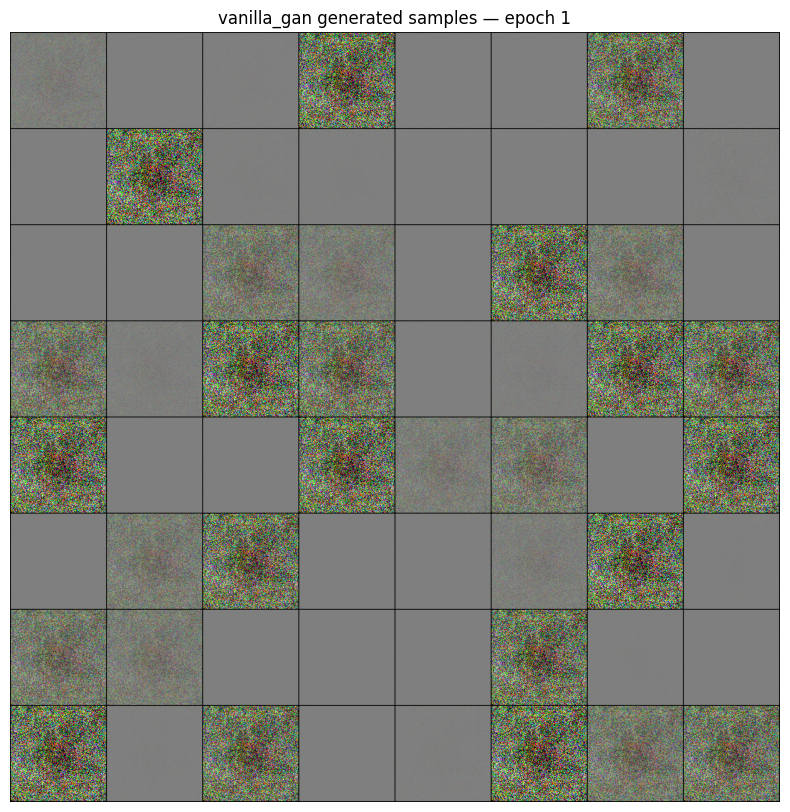

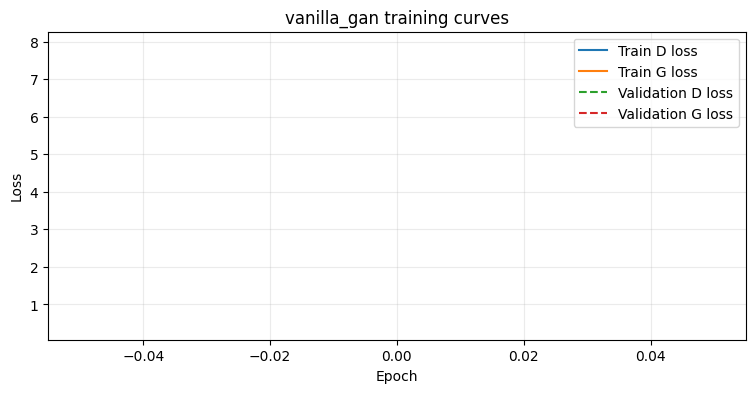

Saved: /content/drive/MyDrive/assignment2_gan_outputs/vanilla_gan_loss_curves.png


In [11]:
vanilla_G = VanillaGenerator().to(device)
vanilla_D = VanillaDiscriminator().to(device)
vanilla_history, vanilla_samples = train_gan(
    "vanilla_gan", vanilla_G, vanilla_D,
    epochs=EPOCHS,
    label_smoothing=True,
    input_noise_std=0.0,
)

## 10. Train DCGAN

dcgan | epoch 001/1 | D=1.2277 G=1.0343 | val D=1.1968 G=1.0708


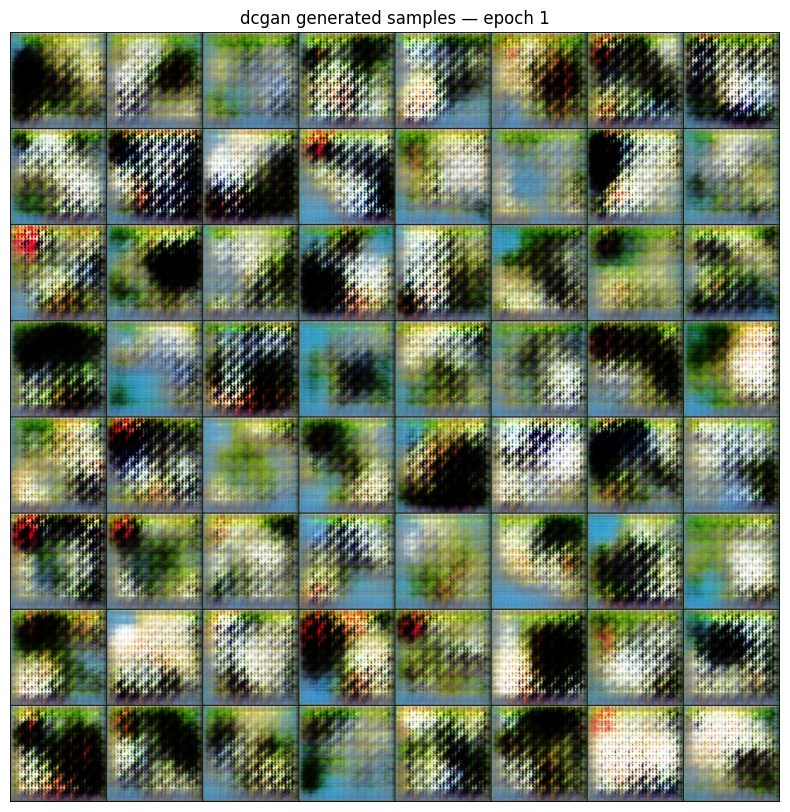

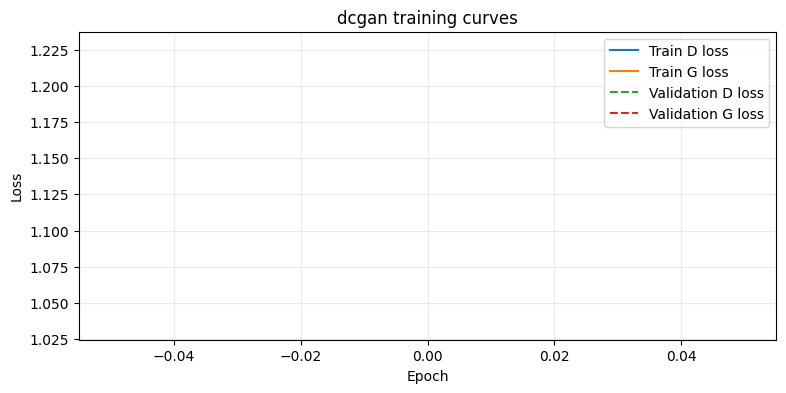

Saved: /content/drive/MyDrive/assignment2_gan_outputs/dcgan_loss_curves.png


In [12]:
dcgan_G = DCGANGenerator().to(device)
dcgan_D = DCGANDiscriminator().to(device)
dcgan_history, dcgan_samples = train_gan(
    "dcgan", dcgan_G, dcgan_D,
    epochs=EPOCHS,
    label_smoothing=True,
    input_noise_std=0.0,
)

## 11. Latent-space interpolation

Interpolate between two latent vectors and visualize the generated sequence. Smooth transitions can indicate that the generator learned a structured mapping, although interpolation alone does not prove high sample quality.

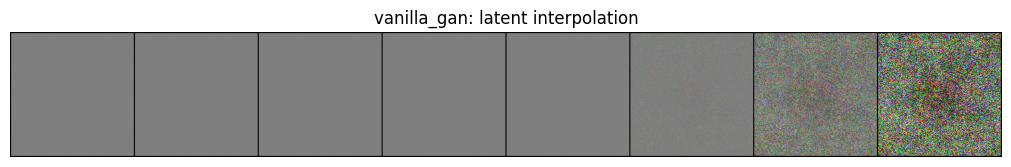

Saved: /content/drive/MyDrive/assignment2_gan_outputs/vanilla_gan_latent_interpolation.png


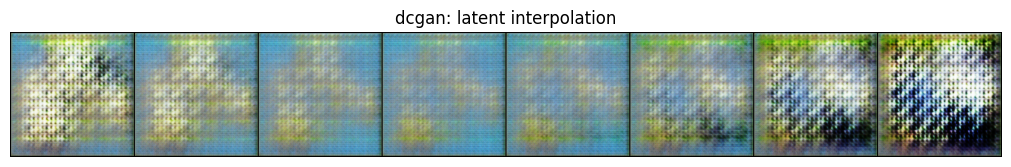

Saved: /content/drive/MyDrive/assignment2_gan_outputs/dcgan_latent_interpolation.png


In [13]:
@torch.no_grad()
def save_latent_interpolation(G, model_name, steps=8):
    G.eval()
    z1 = torch.randn(1, LATENT_DIM, device=device)
    z2 = torch.randn(1, LATENT_DIM, device=device)
    alphas = torch.linspace(0, 1, steps, device=device)
    zs = torch.cat([(1-a)*z1 + a*z2 for a in alphas], dim=0)
    imgs = G(zs).cpu()
    grid = utils.make_grid(imgs, nrow=steps, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(steps * 1.6, 2.5))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    plt.axis("off"); plt.title(f"{model_name}: latent interpolation")
    path = OUTPUT_DIR / f"{model_name}_latent_interpolation.png"
    plt.savefig(path, bbox_inches="tight"); plt.show(); plt.close()
    G.train()
    print("Saved:", path)

save_latent_interpolation(vanilla_G, "vanilla_gan")
save_latent_interpolation(dcgan_G, "dcgan")

## 12. Quantitative evaluation: FID when available, otherwise a proxy

FID normally compares feature distributions of real and generated images; lower is better. It is not a pixelwise accuracy metric. Inception Score can be less meaningful for a small or specialized dataset.

This cell attempts FID with `torchmetrics`. If the dependency or pretrained feature extractor is unavailable, it reports a simple feature-space nearest-neighbor proxy using resized flattened images. **That fallback is not FID and must be labelled as a proxy in the report.**

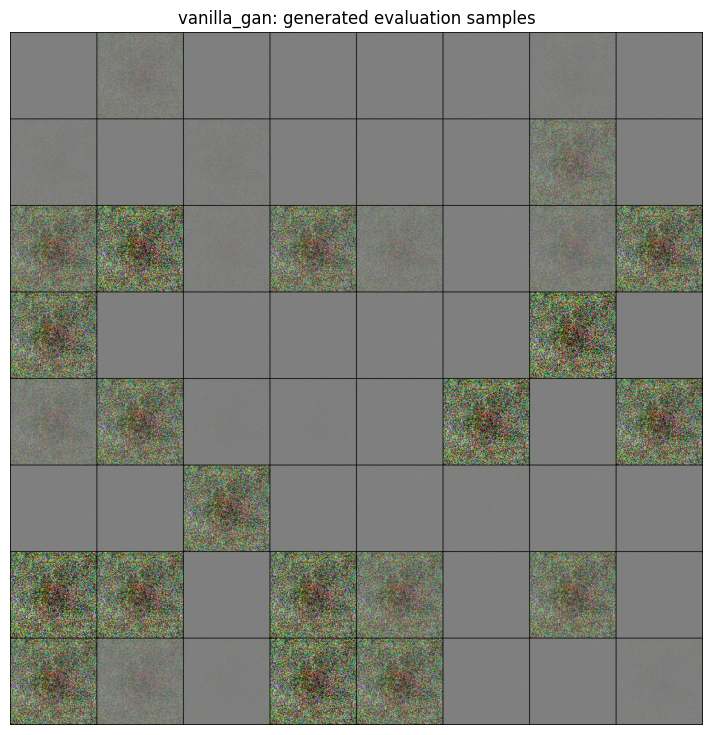

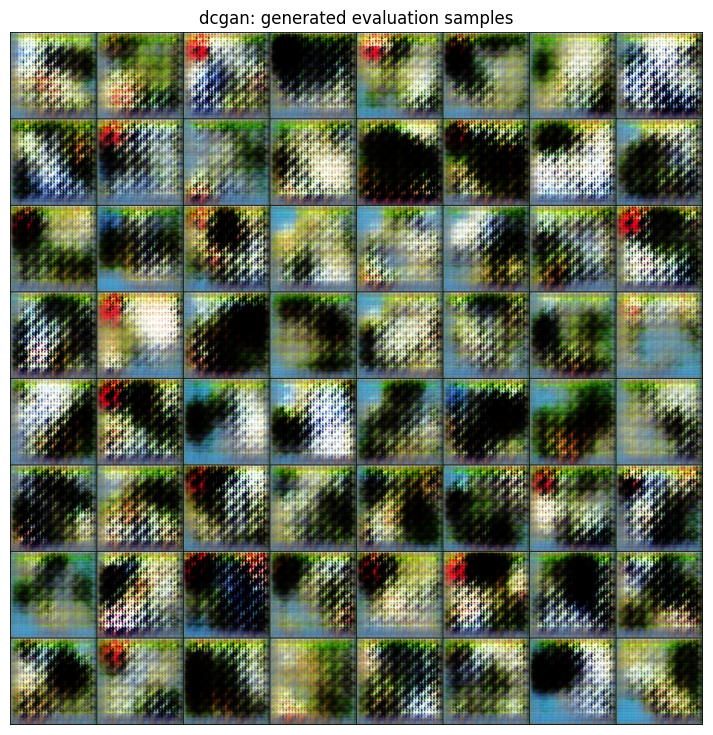

,model,n_real,n_fake,proxy_nearest_neighbor_distance,metric_note,fid_error
0,vanilla_gan,256,256,0.222419,"Pixel-space nearest-neighbor proxy, NOT FID/KID",No module named 'torchmetrics'
1,dcgan,256,256,0.516723,"Pixel-space nearest-neighbor proxy, NOT FID/KID",No module named 'torchmetrics'


In [14]:
@torch.no_grad()
def generate_images(G, n):
    G.eval()
    chunks = []
    remaining = n
    while remaining > 0:
        bs = min(BATCH_SIZE, remaining)
        fake = G(torch.randn(bs, LATENT_DIM, device=device)).cpu()
        # Convert from [-1,1] to [0,1].
        chunks.append(((fake + 1) / 2).clamp(0, 1))
        remaining -= bs
    G.train()
    return torch.cat(chunks, dim=0)


@torch.no_grad()
def collect_real_images(loader, n):
    chunks, remaining = [], n
    for real, _ in loader:
        bs = min(real.size(0), remaining)
        chunks.append(((real[:bs].cpu() + 1) / 2).clamp(0, 1))
        remaining -= bs
        if remaining <= 0:
            break
    return torch.cat(chunks, dim=0)


def proxy_nearest_neighbor_distance(real_imgs, fake_imgs, side=16):
    # Explicitly a rough pixel-space proxy, not FID/KID.
    real = torch.nn.functional.interpolate(real_imgs, size=(side, side), mode="bilinear", align_corners=False)
    fake = torch.nn.functional.interpolate(fake_imgs, size=(side, side), mode="bilinear", align_corners=False)
    real = real.flatten(1); fake = fake.flatten(1)
    real = torch.nn.functional.normalize(real, dim=1)
    fake = torch.nn.functional.normalize(fake, dim=1)
    distances = torch.cdist(fake, real, p=2)
    return distances.min(dim=1).values.mean().item()


def evaluate_generator(G, model_name, n_samples=256):
    real = collect_real_images(test_loader, min(n_samples, len(test_dataset)))
    fake = generate_images(G, len(real))
    results = {"model": model_name, "n_real": int(len(real)), "n_fake": int(len(fake))}
    try:
        from torchmetrics.image.fid import FrechetInceptionDistance
        fid_metric = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
        # Torchmetrics expects uint8 [0,255] unless normalize=True, where float [0,1] is accepted.
        fid_metric.update(real.to(device), real=True)
        fid_metric.update(fake.to(device), real=False)
        results["FID"] = float(fid_metric.compute().item())
        results["metric_note"] = "FID; lower is better"
    except Exception as exc:
        results["proxy_nearest_neighbor_distance"] = proxy_nearest_neighbor_distance(real, fake)
        results["metric_note"] = "Pixel-space nearest-neighbor proxy, NOT FID/KID"
        results["fid_error"] = str(exc)[:300]

    # Save a sample grid from the generated test-evaluation batch.
    grid = utils.make_grid(fake[:64], nrow=8)
    plt.figure(figsize=(9, 9))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1)); plt.axis("off")
    plt.title(f"{model_name}: generated evaluation samples")
    plt.savefig(OUTPUT_DIR / f"{model_name}_evaluation_grid.png", bbox_inches="tight")
    plt.show(); plt.close()
    return results

vanilla_metrics = evaluate_generator(vanilla_G, "vanilla_gan")
dcgan_metrics = evaluate_generator(dcgan_G, "dcgan")
metrics = [vanilla_metrics, dcgan_metrics]
with open(OUTPUT_DIR / "quantitative_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
pd.DataFrame(metrics)

## 13. Experiment: sensitivity to latent dimension, batch size, and learning rate

The assignment asks for sensitivity experiments. This cell provides a small experiment plan/table to fill in after running controlled comparisons. For a full comparison, rerun the training cells with one variable changed at a time and keep the data split and epoch count fixed. Do not compare runs that changed several settings simultaneously.

In [15]:
experiment_plan = pd.DataFrame([
    {"experiment": "Baseline", "latent_dim": LATENT_DIM, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "stabilization": "one-sided label smoothing"},
    {"experiment": "Latent dim 64", "latent_dim": 64, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "stabilization": "same as baseline"},
    {"experiment": "Latent dim 128", "latent_dim": 128, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "stabilization": "same as baseline"},
    {"experiment": "Lower learning rate", "latent_dim": LATENT_DIM, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE/2, "stabilization": "same as baseline"},
    {"experiment": "No label smoothing", "latent_dim": LATENT_DIM, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "stabilization": "disabled"},
])
experiment_plan

,experiment,latent_dim,batch_size,learning_rate,stabilization
0,Baseline,100,16,0.0002,one-sided label smoothing
1,Latent dim 64,64,16,0.0002,same as baseline
2,Latent dim 128,128,16,0.0002,same as baseline
3,Lower learning rate,100,16,0.0001,same as baseline
4,No label smoothing,100,16,0.0002,disabled


## 14. Compare the two GANs and save the report summary

Use observed results from the run. Do not invent conclusions: GAN losses alone do not necessarily indicate image quality. Compare loss curves, epoch sample grids, interpolation, and FID/KID or a clearly named proxy.

In [16]:
comparison = pd.DataFrame([
    {"Model": "Vanilla GAN", "Final train D loss": vanilla_history["d_loss"][-1],
     "Final train G loss": vanilla_history["g_loss"][-1], **vanilla_metrics},
    {"Model": "DCGAN", "Final train D loss": dcgan_history["d_loss"][-1],
     "Final train G loss": dcgan_history["g_loss"][-1], **dcgan_metrics},
])
display(comparison)
comparison.to_csv(OUTPUT_DIR / "gan_comparison.csv", index=False)
with open(OUTPUT_DIR / "assignment2_summary.json", "w") as f:
    json.dump({
        "image_size": IMAGE_SIZE,
        "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "betas": [BETA1, BETA2],
        "seed": SEED,
        "class_names": class_names,
        "vanilla_metrics": vanilla_metrics,
        "dcgan_metrics": dcgan_metrics,
        "notes": [
            "GAN losses are diagnostics and not direct image-quality metrics.",
            "If FID failed, report the fallback as a proxy, not as FID.",
            "Do not report metrics until this notebook has been run on the dataset."
        ]
    }, f, indent=2)
print("Saved results to", OUTPUT_DIR)

,Model,Final train D loss,Final train G loss,model,n_real,n_fake,proxy_nearest_neighbor_distance,metric_note,fid_error
0,Vanilla GAN,1.039219,7.888118,vanilla_gan,256,256,0.222419,"Pixel-space nearest-neighbor proxy, NOT FID/KID",No module named 'torchmetrics'
1,DCGAN,1.227665,1.034256,dcgan,256,256,0.516723,"Pixel-space nearest-neighbor proxy, NOT FID/KID",No module named 'torchmetrics'


Saved results to /content/drive/MyDrive/assignment2_gan_outputs
